In [1]:
import pandas as pd
import numpy as np

import os, sys, gc, time, warnings, pickle, psutil, random

from tqdm import tqdm
from math import ceil
from sklearn.preprocessing import LabelEncoder

In [2]:
grid_df = pd.read_parquet('train_val.parquet')
grid_df = grid_df.dropna(subset=['demand'])

In [3]:
m = grid_df.id=='HOBBIES_1_288_CA_1'
sales_ts = grid_df.loc[m,'demand'].values
sales_ts

array([ 7.,  1.,  4.,  5.,  6.,  3.,  0.,  0.,  7.,  2.,  6.,  2.,  0.,
        5.,  4.,  3.,  0.,  0.,  0.,  0.,  0.,  0., 14.,  4.,  1.,  1.,
        1.,  5.,  6.,  1.,  6., 14.,  1.,  0.,  0.,  4.,  2.,  4.,  7.,
        3.,  1.,  2.,  3.,  6.,  4.,  2.,  0.,  1.,  4.,  1.,  2.,  1.,
       11.,  2.,  1.,  3.,  5., 10.,  2.,  4.,  7.,  2.,  0.,  0.,  0.,
        4.,  0.,  8., 12.,  0.,  0.,  0.,  5.,  2., 14.,  0.,  0.,  1.,
        2.,  7.,  1.,  8.,  4.,  3.,  2.,  0.,  2., 13.,  4.,  2.,  0.,
       13.,  4.,  5.,  0.,  9.,  6.,  6.,  3.,  2.,  6.,  0.,  0.,  6.,
        0.,  4.,  0.,  3., 11.,  0.,  0.,  2., 10.,  7.,  4.,  2.,  5.,
        0.,  1.,  3.,  1.,  4.,  2.,  3., 24.,  0.,  3., 24.,  2.,  4.,
       10.,  2., 22., 11.,  8.,  0.,  8.,  7.,  2.,  6.,  9.,  7.,  6.,
        7.,  1.,  8.,  0.,  2.,  5., 12.,  0.,  0.,  0., 14.,  3.,  2.,
       13.,  3.,  5.,  0.,  4., 15.,  0.,  0.,  0.,  0.,  0.,  5.,  0.,
        6.,  3.,  4.,  0.,  0.,  0.,  4.,  0.,  0.,  0.,  0.,  0

In [4]:
def gap_finder(ts):
    
    # this function finds gaps and calculates their length:
    ts = (~(ts > 0)).astype(int)

    for i, val in enumerate(ts):
        if val == 0: 
            continue
        else: 
            ts[i] += ts[i-1]
            ts[i-1] = -1
    return ts

def gap_counter(ts):
    
    # value_counts for gaps lengths
    
    counts = np.unique(ts, return_counts=True)
    return dict(zip(counts[0], counts[1]))

m = grid_df.id=='HOBBIES_1_288_CA_1'

sales_gaps = gap_counter(gap_finder(grid_df.loc[m,'demand'].values))
sales_gaps

{-1: 410, 0: 375, 1: 67, 2: 35, 3: 14, 4: 4, 5: 3, 6: 2, 9: 1, 10: 1, 169: 1}

In [5]:
# Lets try to build a synthetic series with gaps.
# We assume products have a constant chance of being sold on any particular day.
# So for every day we will flip an unfair coin with probability of sale equal to 'dates_with sale'/'all_dates'
# >>>This might be an oversimplistic assumption, a moving window might be used instead.

def synth_sales(gaps_dict, min_gap=1000):
    
    sum_sale_days = gaps_dict.get(0, 0)  # Sẽ trả về 0 nếu không có key 0 # key '0' gives number of days with sales
    sum_days = sum(gaps_dict.values()) # sum of all keys - number of all days
    
    # Sum of days in gaps longer than minimum gap length:
    sum_gap_length = sum([k for k in [*sales_gaps.keys()] if k > min_gap])
    
    # Exlude all the gaps longer than min_gap_length from probability calculation:
    p = sum_sale_days/(sum_days-sum_gap_length)
    
    return np.random.binomial(1, p, sum(gaps_dict.values()))

synth_sales_gaps = gap_counter(gap_finder(synth_sales(sales_gaps)))
synth_sales_gaps

{-1: 554, 0: 143, 1: 80, 2: 46, 3: 41, 4: 19, 5: 14, 6: 8, 7: 3, 8: 3, 10: 2}

In [6]:
# As you can see we dont have results > 20. 
# To make sure this is a consistent result lets run simulation 1,000 times:
# >>>> n equal 1,000 might be an overshot for some ids.

n=1000

sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps))) for i in range(n)])
gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()
gap_length_prob

-1     538.047
 0     154.583
 1      90.090
 2      53.423
 3      31.663
 4      18.525
 5      10.809
 6       6.572
 7       3.849
 8       2.292
 9       1.272
 10      0.756
 11      0.434
 12      0.265
 13      0.184
 14      0.103
 15      0.043
 16      0.034
 17      0.023
 18      0.013
 19      0.007
 20      0.003
 21      0.006
 22      0.001
 23      0.002
 26      0.001
dtype: float64

In [7]:
# The shortest gap that has been seen in less than 5% of simulated series:
min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)
min_gap_length

15

In [8]:
# Now we exclude the gaps longer than min_gap_length from 'probability of sale' calculation, 
# because we assume them to be non-random.
# Run the simulation recursively until the min_gap_length does not decrease:

n=1000
new_min_gap_length = 0

while new_min_gap_length != min_gap_length:
    
    if new_min_gap_length!=0: min_gap_length=new_min_gap_length

    sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps, min_gap_length))) for i in range(n)])
    gap_length_prob = (sym_df.sum(axis=0)/n).sort_index()

    # Lets find the shortes gap that has been seen in les than 5% of simulated series:
    new_min_gap_length = min(gap_length_prob[gap_length_prob<0.05].index)

min_gap_length

13

In [9]:
# Finally we need to make a feature 'out_of_stock' for the product:
m = grid_df.id=='HOBBIES_1_288_CA_1'
idx = grid_df.loc[m,'demand'].index

gf = pd.Series(gap_finder(grid_df.loc[m,'demand'].values), index = idx)
gf = gf.replace(-1,np.nan).fillna(method='backfill') 
gf = gf > min_gap_length
gf

C:\Users\ASUS\AppData\Local\Temp\ipykernel_6268\2685504888.py:6: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  gf = gf.replace(-1,np.nan).fillna(method='backfill')


280         False
30770       False
61260       False
91750       False
122240      False
            ...  
27685200    False
27715690    False
27746180    False
27776670    False
27807160    False
Length: 913, dtype: bool

In [11]:
from tqdm import tqdm
import numpy as np
import pandas as pd

grid_df['out_of_stock'] = 0
n = 1000
prods = list(grid_df.id.unique())[:5]
gap_length_list = []

for prod_id in tqdm(prods):
    m = grid_df.id == prod_id
    idx = grid_df.loc[m, 'demand'].index

    sales_gaps = gap_counter(gap_finder(grid_df.loc[m, 'demand'].values))
    sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps))) for _ in range(n)])
    gap_length_prob = (sym_df.sum(axis=0) / n).sort_index()

    # Nếu không có giá trị nào < 0.05 thì bỏ qua sản phẩm này
    if (gap_length_prob < 0.05).sum() == 0:
        continue

    min_gap_length = min(gap_length_prob[gap_length_prob < 0.05].index)
    new_min_gap_length = 0

    while new_min_gap_length < min_gap_length:
        if new_min_gap_length != 0:
            min_gap_length = new_min_gap_length

        sym_df = pd.DataFrame([gap_counter(gap_finder(synth_sales(sales_gaps, min_gap_length))) for _ in range(n)])
        gap_length_prob = (sym_df.sum(axis=0) / n).sort_index()

        if (gap_length_prob < 0.05).sum() == 0:
            break
        new_min_gap_length = min(gap_length_prob[gap_length_prob < 0.05].index)

    gf = pd.Series(gap_finder(grid_df.loc[m, 'demand'].values), index=idx)
    gf = gf.replace(-1, np.nan).fillna(method='backfill')
    gf = gf > min_gap_length
    grid_df.loc[m, 'out_of_stock'] = gf * 1
    gap_length_list.append(min_gap_length)

  0%|          | 0/5 [00:00<?, ?it/s]C:\Users\ASUS\AppData\Local\Temp\ipykernel_6268\2104339594.py:37: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  gf = gf.replace(-1, np.nan).fillna(method='backfill')
 20%|██        | 1/5 [00:02<00:09,  2.37s/it]C:\Users\ASUS\AppData\Local\Temp\ipykernel_6268\2104339594.py:37: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  gf = gf.replace(-1, np.nan).fillna(method='backfill')
 40%|████      | 2/5 [00:04<00:07,  2.45s/it]C:\Users\ASUS\AppData\Local\Temp\ipykernel_6268\2104339594.py:37: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  gf = gf.replace(-1, np.nan).fillna(method='backfill')
 60%|██████    | 3/5 [00:07<00:05,  2.64s/it]C:\Users\ASUS\AppData\Local\Temp\ipykernel_6268\2104339594.py:3

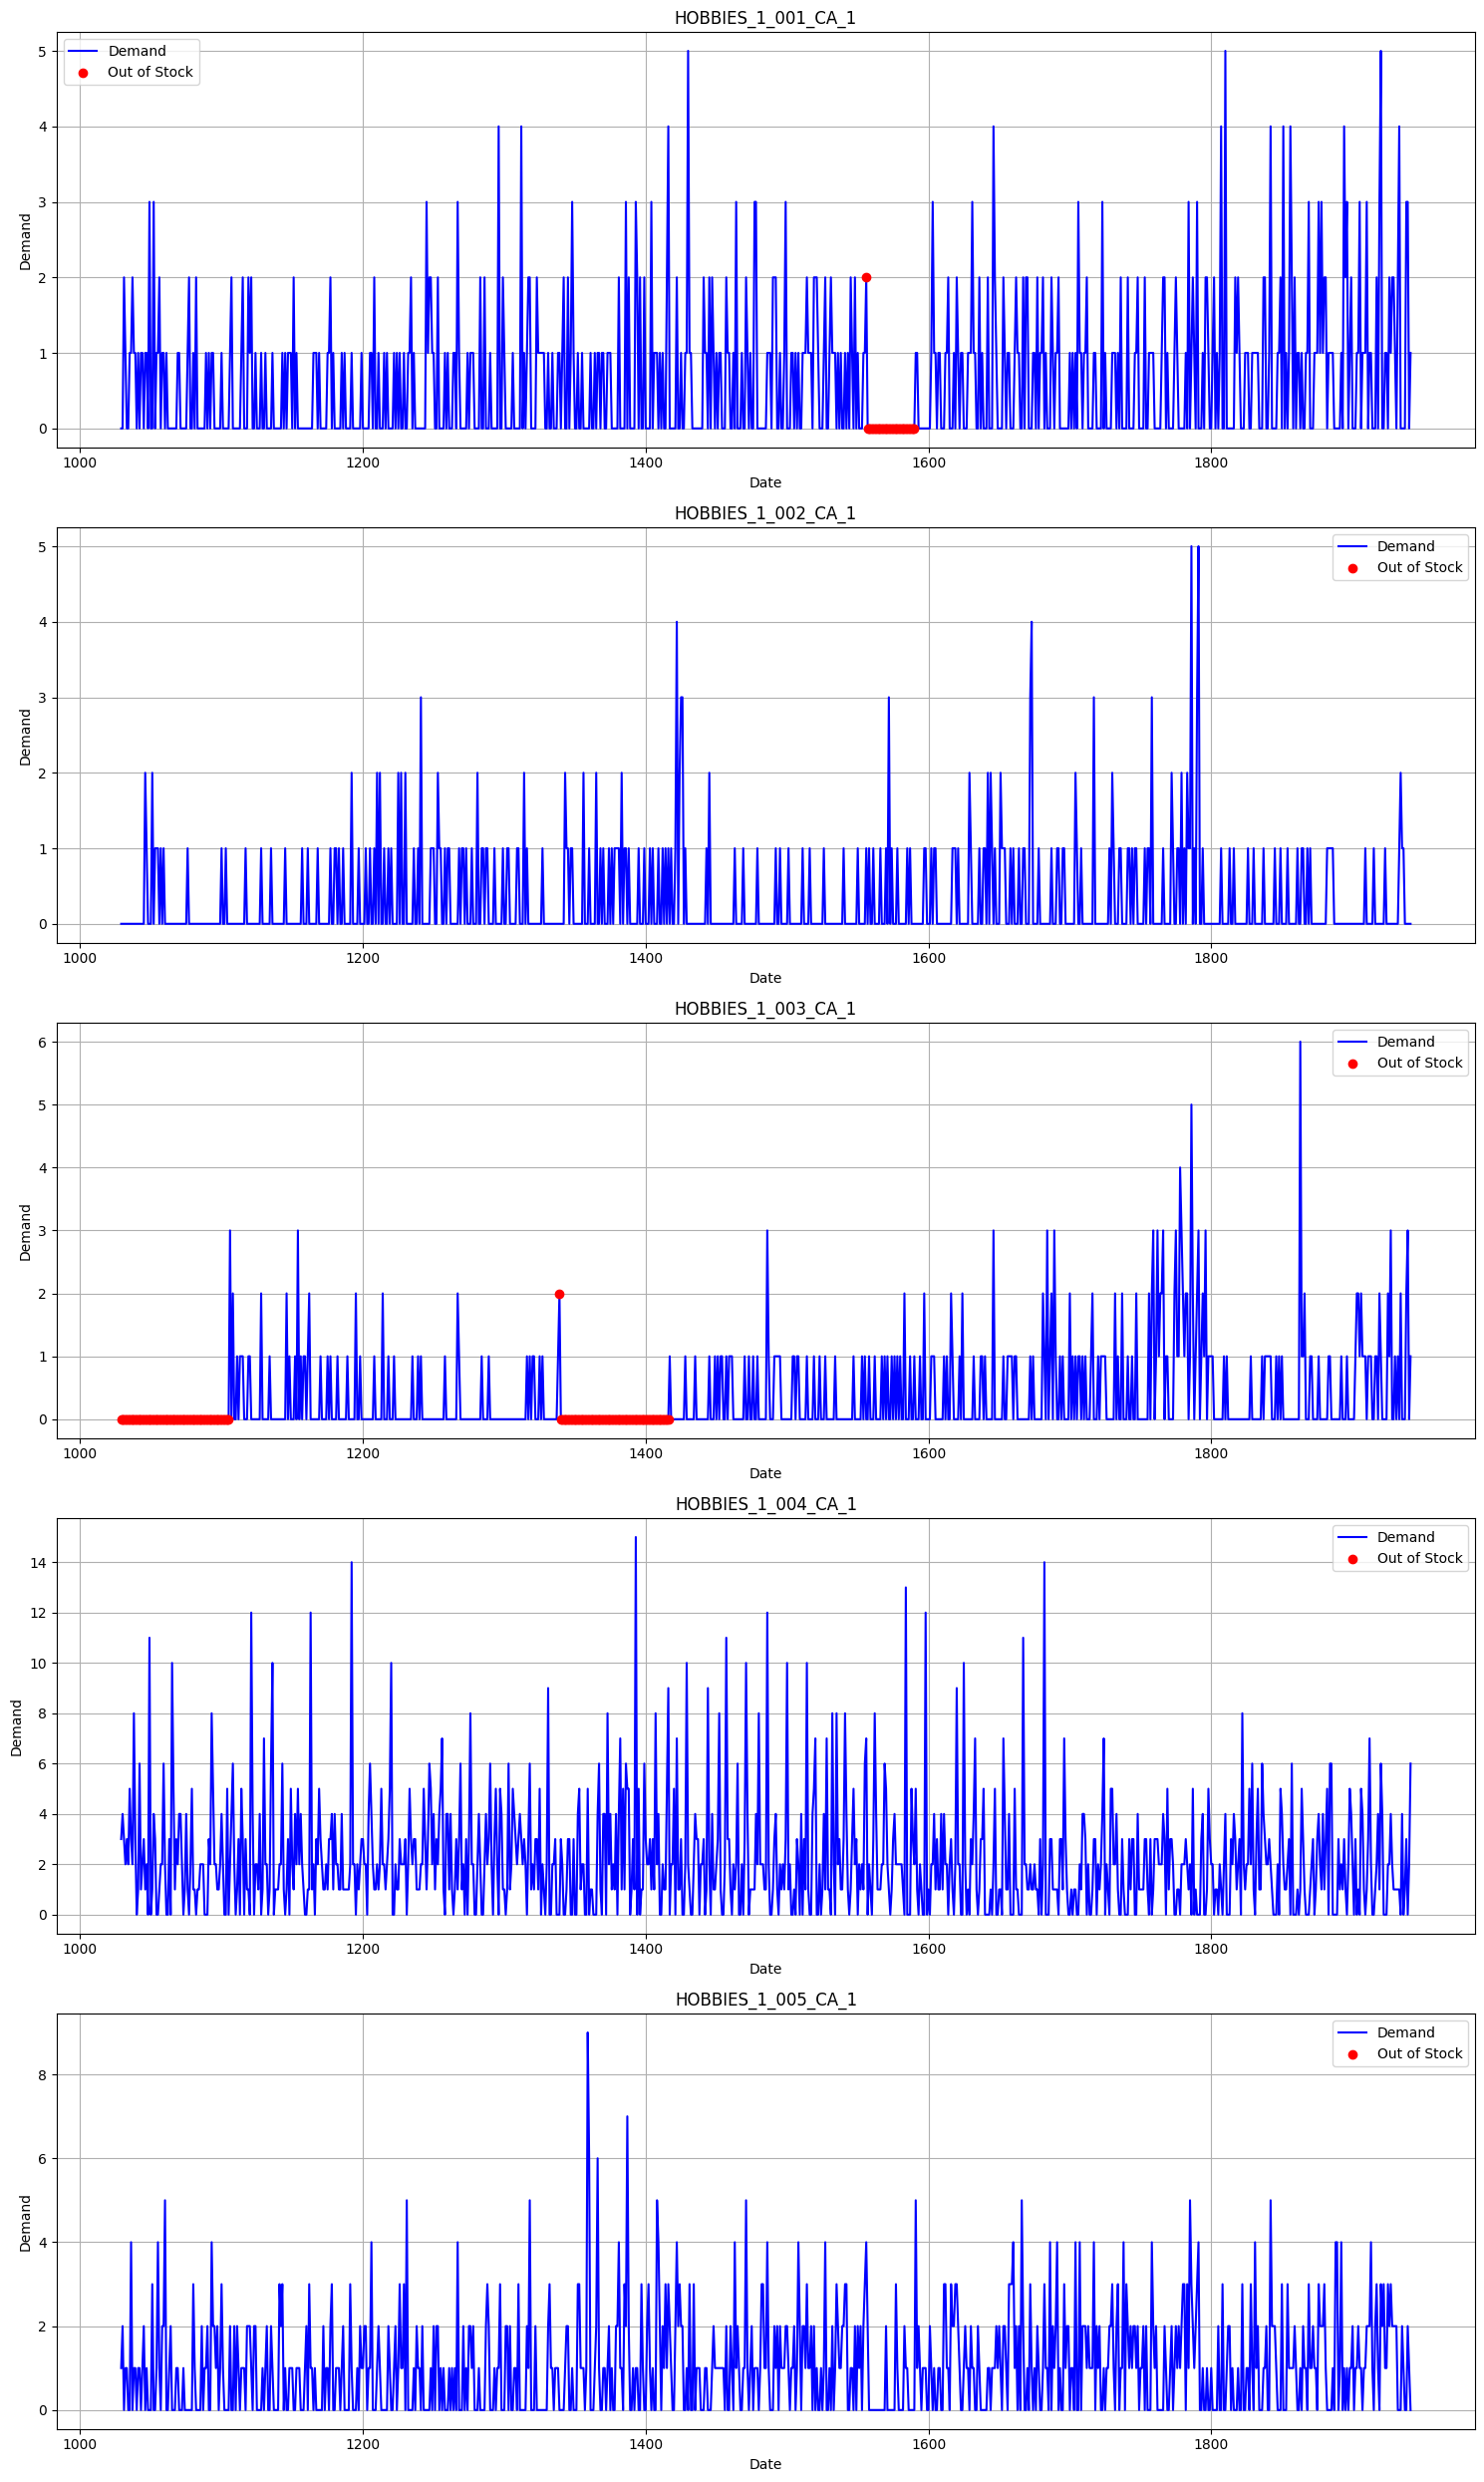

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 25))

for i, prod_id in enumerate(prods):
    plt.subplot(5, 1, i + 1)
    m = grid_df.id == prod_id
    prod_df = grid_df.loc[m]

    plt.plot(prod_df['d'], prod_df['demand'], label='Demand', color='blue')

    out_days = prod_df[prod_df['out_of_stock'] == 1]
    plt.scatter(out_days['d'], out_days['demand'], color='red', label='Out of Stock', zorder=5)

    plt.title(f'{prod_id}')
    plt.xlabel('Date')
    plt.ylabel('Demand')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()